# Continuous cooling versus discrete pp collisions: time comparison

Compare proton **total-energy spectra** $dN/d\ln E$ at $t=10^8$ and $10^9$ yr, where $E=T+m_pc^2$ and $T$ is kinetic energy. No secondary pion or photon spectrum is calculated.

The three cases match `pion_decay_comparison.ipynb`: log-uniform kinetic-energy injection, monoenergetic injection with energy-dependent cross section, and monoenergetic injection with fixed cross section. Each case has 100,000 equal-weight protons, $n_H=1$ cm$^{-3}$ and $\kappa=0.5$, with $v=c$ and no escape or other losses.

Run from the project directory or `output/`. The existing binary files contain no time metadata: `pp_loss_comparison.bin` is assigned to $10^8$ yr, as in the reference notebook; `pp_loss_comparison_t1e9.bin` is assigned to $10^9$ yr, as in the current C++ generator. Regenerating the current generator only overwrites the latter file.


In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

file_t1e8 = Path('pp_loss_comparison.bin')
file_t1e9 = Path('pp_loss_comparison_t1e9.bin')
if not file_t1e8.exists():
    file_t1e8 = Path('output') / file_t1e8
if not file_t1e9.exists():
    file_t1e9 = Path('output') / file_t1e9

N_particles = 100000  # per injection case
T_min = 10.0          # initial kinetic energy, GeV
T_max = 1e6           # GeV
T_mono = 1000.0       # GeV
m_p_GeV = 0.9382720813  # proton rest energy m_p c^2, GeV
nH = 1.0             # cm^-3
kappa = 0.5
c_cm_s = 2.99792458e10
yr2s = 31557600.0
T_threshold = 0.2797  # kinetic-energy threshold, GeV
times_yr = [1e8, 1e9]
time_labels = [r'$t=10^8$ yr', r'$t=10^9$ yr']
labels = ['Log-uniform, energy-dependent sigma',
          'Mono, energy-dependent sigma', 'Mono, fixed sigma']

# Shared display settings for readable notebook figures.
plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'axes.linewidth': 1.2,
    'figure.dpi': 120,
})
time_colors = ['#0072B2', '#D55E00']  # blue: 1e8 yr; vermilion: 1e9 yr
initial_color = '#555555'


## Load the two collision runs

The writer in `pion_decay_mc.cpp` stores four native-endian float64 values per record: case ID, initial kinetic energy [GeV], final kinetic energy [GeV], and collision count. Rest energy is added only when constructing the total-energy spectra.


In [2]:
data_t1e8 = np.fromfile(file_t1e8, dtype='=f8').reshape(-1, 4)
data_t1e9 = np.fromfile(file_t1e9, dtype='=f8').reshape(-1, 4)
for data in [data_t1e8, data_t1e9]:
    assert data.shape == (3 * N_particles, 4)
    assert np.all(data[:, 2] > 0)
    assert np.allclose(data[:, 2], data[:, 1] * (1 - kappa)**data[:, 3])
    for j in range(3):
        assert np.sum(data[:, 0] == j) == N_particles
assert np.array_equal(data_t1e8[:, :2], data_t1e9[:, :2])

case_id = data_t1e8[:, 0].astype(int)
T_initial = data_t1e8[:, 1]
T_final_t1e8 = data_t1e8[:, 2]
T_final_t1e9 = data_t1e9[:, 2]
T_final_runs = [T_final_t1e8, T_final_t1e9]
E_initial = T_initial + m_p_GeV


## Continuous-cooling reference

Use the same cross section as the C++ writer, in cm$^2$:
$$\sigma(T)=(30.7-0.96L+0.18L^2)[1-(T_{\rm th}/T)^{1.9}]^3\,10^{-27},\quad L=\ln(T/T_{\rm th}),$$
with zero cross section below threshold. Continuous cooling solves
$$\frac{dT}{dt}=-\kappa\Gamma(T)T,\qquad \Gamma(T)=n_Hc\sigma(T).$$
The fixed-cross-section case instead has $T(t)=T_0\exp[-\kappa\Gamma(T_{\rm mono})t]$.


t=1e+08 yr: maximum cooling-map refinement change = 5.61e-08
t=1e+09 yr: maximum cooling-map refinement change = 1.68e-08


Text(0, 0.5, 'collision timescale [yr]')

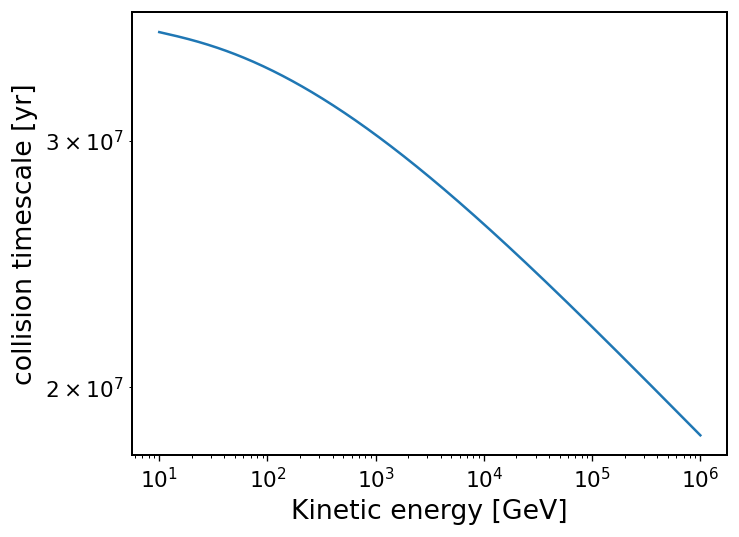

In [16]:
def sigma_pp(T):
    T = np.asarray(T, dtype=float)
    safe_T = np.maximum(T, T_threshold)
    L = np.log(safe_T / T_threshold)
    sigma = (30.7 - 0.96 * L + 0.18 * L**2) * (1 - (T_threshold / safe_T)**1.9)**3 * 1e-27
    return np.where(T > T_threshold, sigma, 0.0)


def collision_rate(T):
    return nH * c_cm_s * sigma_pp(T) * yr2s  # yr^-1


def continuous_solution(T_end, N_grid, rtol):
    T0_grid = np.logspace(np.log10(T_min), np.log10(T_max), N_grid)
    # Include the monoenergetic input exactly in the reference grid.
    T0_grid = np.sort(np.append(T0_grid, T_mono))

    # solve_ivp numerically integrates d ln(T)/dq for all grid energies,
    # where q=t/T_end. These are independent scalar cooling equations.
    # Integrating ln(T) keeps energies positive; the result is a mapping
    # from initial kinetic energy to final kinetic energy, both in GeV.
    def rhs(q, logT):
        return -T_end * kappa * collision_rate(np.exp(logT))

    solution = solve_ivp(rhs, (0, 1), np.log(T0_grid),
                         rtol=rtol, atol=rtol * 0.01)
    assert solution.success, solution.message
    Tf_grid = np.exp(solution.y[:, -1])
    # np.interp linearly interpolates ln(T_final) against ln(T_initial),
    # applying the cooling map to the same injected particles as the MC.
    T_continuous = np.exp(np.interp(np.log(T_initial), np.log(T0_grid),
                                    np.log(Tf_grid)))
    fixed = case_id == 2
    T_continuous[fixed] = T_initial[fixed] * np.exp(-kappa * collision_rate(T_mono) * T_end)
    return T_continuous


T_continuous_runs = []
for T_end in times_yr:
    T_continuous = continuous_solution(T_end, 4097, 1e-10)
    T_check = continuous_solution(T_end, 8193, 1e-12)
    refinement_error = np.max(np.abs(T_continuous / T_check - 1))
    assert refinement_error < 1e-5
    print(f't={T_end:.0e} yr: maximum cooling-map refinement change = {refinement_error:.2e}')
    T_continuous_runs.append(T_continuous)

T_arr = np.logspace(1, 6, 501)
plt.plot(T_arr, 1 / collision_rate(T_arr))
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Kinetic energy [GeV]")
plt.ylabel("collision timescale [yr]")


In [14]:
sigma_pp(1000)

array(3.48949727e-26)

## Total-energy spectra at each time

All populations and both times use the same total-energy bins within each injection case:
$$\left(\frac{dN}{d\ln E}\right)_i=\frac{N_i}{\ln(E_{i+1}/E_i)}.$$
The normalization is the absolute number of protons per natural-log energy interval. Monoenergetic peaks are plotted as bin averages, so their heights depend on bin width. At low kinetic energy, adding rest energy compresses spectral differences on the total-energy axis.


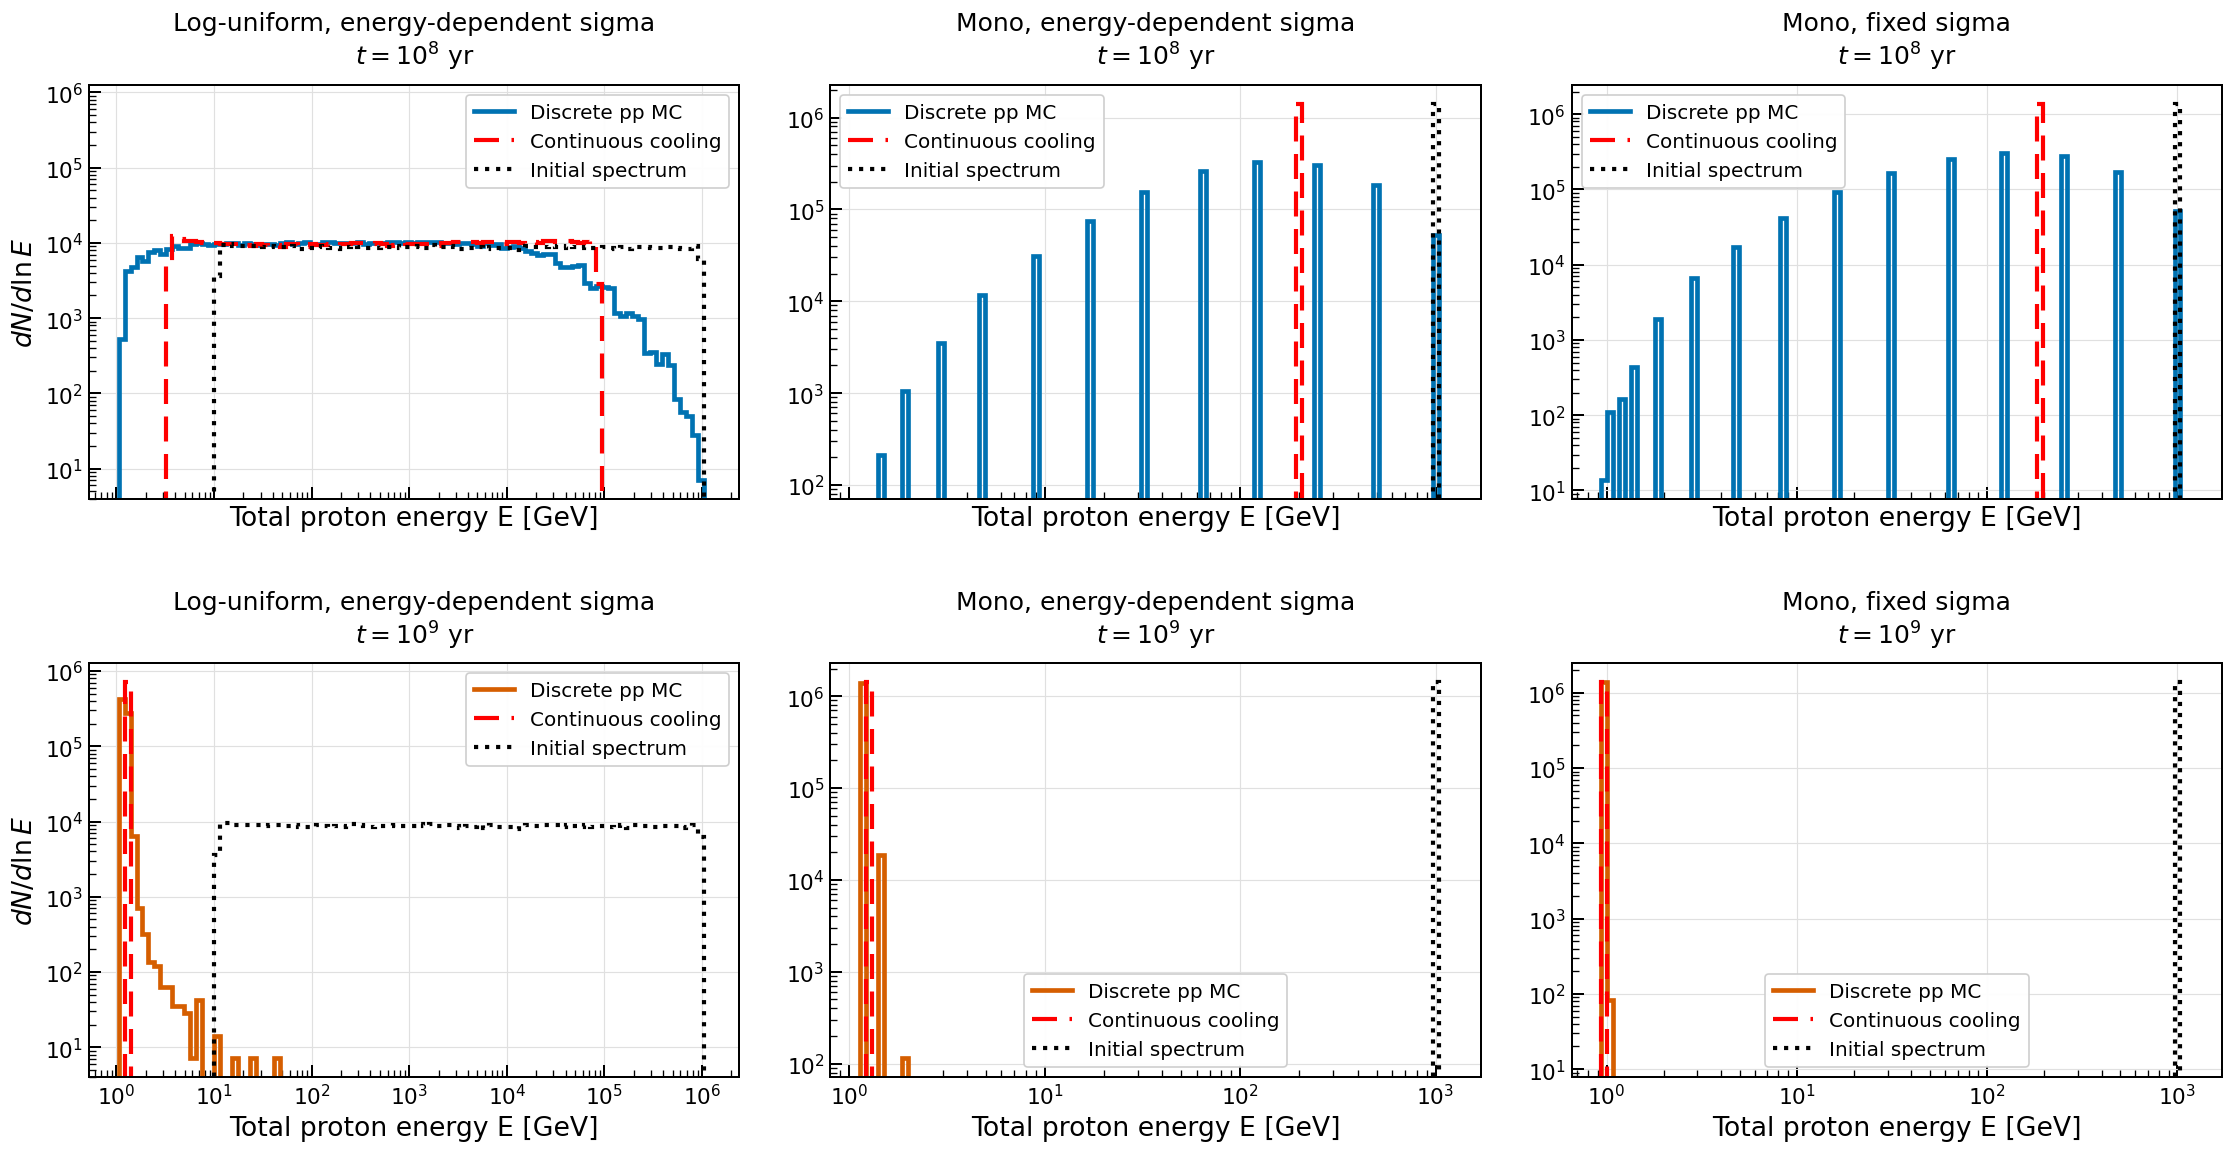

In [9]:
E_bins_cases = []
initial_spectra = []
mc_spectra = [[], []]
continuous_spectra = [[], []]
for j in range(3):
    selected = case_id == j
    T_low = T_initial[selected].min()
    for k in range(2):
        T_low = min(T_low, T_final_runs[k][selected].min(),
                    T_continuous_runs[k][selected].min())
    E_low = m_p_GeV + 0.8 * T_low
    E_high = m_p_GeV + 1.2 * T_initial[selected].max()
    E_bins = np.logspace(np.log10(E_low), np.log10(E_high), 100)
    delta_lnE = np.log(E_bins[1:] / E_bins[:-1])
    E_bins_cases.append(E_bins)
    counts_initial = np.histogram(E_initial[selected], bins=E_bins)[0]
    assert counts_initial.sum() == N_particles
    initial_spectra.append(counts_initial / delta_lnE)
    for k in range(2):
        E_final = T_final_runs[k][selected] + m_p_GeV
        E_continuous = T_continuous_runs[k][selected] + m_p_GeV
        counts_mc = np.histogram(E_final, bins=E_bins)[0]
        counts_continuous = np.histogram(E_continuous, bins=E_bins)[0]
        assert counts_mc.sum() == N_particles
        assert counts_continuous.sum() == N_particles
        mc_spectra[k].append(counts_mc / delta_lnE)
        continuous_spectra[k].append(counts_continuous / delta_lnE)

fig, axes = plt.subplots(2, 3, figsize=(19, 10), sharex='col', sharey='col')
for k in range(2):
    for j in range(3):
        ax = axes[k, j]
        E_bins = E_bins_cases[j]
        ax.stairs(mc_spectra[k][j], E_bins, color=time_colors[k], linewidth=2.8,
                  label='Discrete pp MC')
        ax.stairs(continuous_spectra[k][j], E_bins, color="red",
                  linestyle=(0, (6, 3)), linewidth=2.5, label='Continuous cooling')
        ax.stairs(initial_spectra[j], E_bins, color="black",
                  linestyle=':', linewidth=2.5, label='Initial spectrum')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(labels[j] + '\n' + time_labels[k], pad=12)
        ax.set_xlabel('Total proton energy E [GeV]')
        ax.tick_params(which='major', direction='in', length=7, width=1.2)
        ax.tick_params(which='minor', direction='in', length=4, width=0.8)
        ax.grid(True, which='major', color='0.88', linewidth=0.7)
        ax.set_axisbelow(True)
        ax.legend(fontsize=12, framealpha=0.95, edgecolor='0.8')
    axes[k, 0].set_ylabel(r'$dN/d\ln E$')
fig.tight_layout(pad=1.5, h_pad=2.5, w_pad=2)
plt.show()


## Direct comparison of the two propagation times

Color identifies propagation time; solid curves show discrete collisions and dashed curves show continuous cooling. The initial spectrum is shared by both runs.


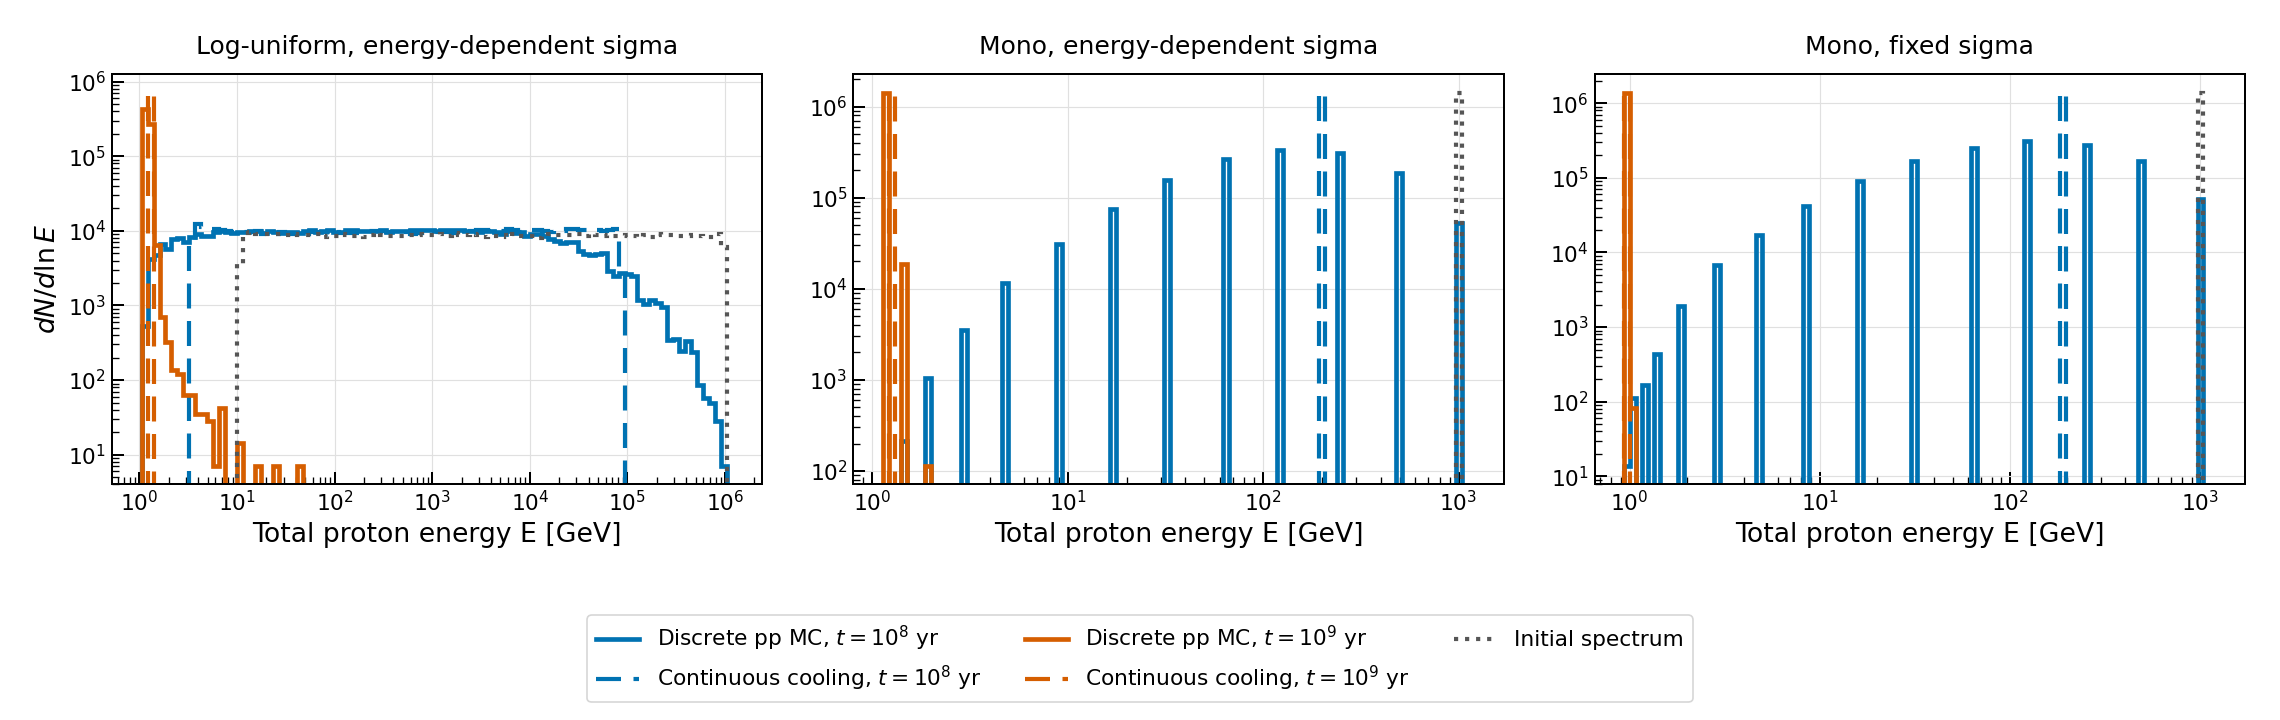

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for j in range(3):
    ax = axes[j]
    E_bins = E_bins_cases[j]
    for k in range(2):
        ax.stairs(mc_spectra[k][j], E_bins, color=time_colors[k], linewidth=2.8,
                  label='Discrete pp MC, ' + time_labels[k])
        ax.stairs(continuous_spectra[k][j], E_bins, color=time_colors[k],
                  linestyle=(0, (6, 3)), linewidth=2.5,
                  label='Continuous cooling, ' + time_labels[k])
    ax.stairs(initial_spectra[j], E_bins, color=initial_color, linestyle=':',
              linewidth=2.5, label='Initial spectrum')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total proton energy E [GeV]')
    ax.set_title(labels[j], pad=12)
    ax.tick_params(which='major', direction='in', length=7, width=1.2)
    ax.tick_params(which='minor', direction='in', length=4, width=0.8)
    ax.grid(True, which='major', color='0.88', linewidth=0.7)
    ax.set_axisbelow(True)
axes[0].set_ylabel(r'$dN/d\ln E$')
# A shared legend below the panels keeps five labels from covering spectra.
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='lower center', ncol=3, fontsize=13,
           frameon=True, edgecolor='0.8', bbox_to_anchor=(0.5, 0.01))
fig.tight_layout(rect=(0, 0.19, 1, 1), pad=1.5, w_pad=2)
plt.show()
